In [ ]:
#### Figure 
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import math
from torch.optim import Adam, LBFGS
from torch.autograd import grad
from torch.autograd.functional import jacobian

# =============================================
# 1. Configuration
# =============================================
class Config:
    m = 1.0
    c = 0.2
    k1_true = 100.0
    k2_true = 150.0
    omega = 90.0

    t_max = 5.0
    num_points = 10000

    chunk_size = 1.0
    adam_epochs = 20_000
    lbfgs_epochs = 200
    lr_model = 1e-4
    lr_params = 1e-3

    if torch.cuda.is_available():
        device = torch.device("cuda")
    elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
        device = torch.device("mps")
    else:
        device = torch.device("cpu")

    torch.manual_seed(1756)
    np.random.seed(1756)


# =============================================
# 2. Data Generator: Duffing Oscillator
# =============================================
class DataGenerator:
    def __init__(self, cfg: Config):
        self.cfg = cfg

    def forcing(self, t: np.ndarray) -> np.ndarray:
        return (
            4000.0 * np.sin(2 * np.pi * self.cfg.omega * t)
            + 3000.0 * np.cos(2 * np.pi * self.cfg.omega * t)
        )

    def rhs(self, t: float, y: np.ndarray) -> list:
        x, v = y
        f = self.forcing(np.array([t]))[0]
        dxdt = v
        dvdt = (f - self.cfg.c * v - self.cfg.k1_true * x - self.cfg.k2_true * x**3) / self.cfg.m
        return [dxdt, dvdt]

    def generate(self) -> (np.ndarray, np.ndarray):
        t_eval = np.linspace(0.0, self.cfg.t_max, self.cfg.num_points)
        sol = solve_ivp(self.rhs, [0.0, self.cfg.t_max], [0.0, 0.0], t_eval=t_eval, method='RK45')
        return sol.t, sol.y[0]


# =============================================
# 3. PINN Model Definition
# =============================================
class FourierLayer(nn.Module):
    def __init__(self, in_features: int, out_features: int, scale: float = 10.0):
        super().__init__()
        B = torch.normal(mean=torch.ones(in_features, out_features), std=1.0) * scale
        self.register_buffer("B", B)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x_proj = 2 * math.pi * x @ self.B
        return torch.cat([torch.sin(x_proj), torch.cos(x_proj)], dim=-1)


class PINNModel(nn.Module):
    def __init__(self, fourier_features=512, hidden_features=64, hidden_layers=2):
        super().__init__()
        self.fourier = FourierLayer(1, fourier_features)
        input_dim = 2 * fourier_features
        layers = [nn.Linear(input_dim, hidden_features), nn.Tanh()]
        for _ in range(hidden_layers - 1):
            layers += [nn.Linear(hidden_features, hidden_features), nn.Tanh()]
        layers.append(nn.Linear(hidden_features, 1))
        self.net = nn.Sequential(*layers)

    def forward(self, t: torch.Tensor) -> torch.Tensor:
        x_embed = self.fourier(t)
        return self.net(x_embed)


# =============================================
# 4. Trainer Class
# =============================================
class Trainer:
    def __init__(self, cfg: Config, t_full: np.ndarray, x_full: np.ndarray):
        self.cfg = cfg
        self.t_full = t_full
        self.x_full = x_full

        self.t_full_tensor = torch.tensor(t_full.reshape(-1, 1), dtype=torch.float32, device=self.cfg.device)
        self.x_full_tensor = torch.tensor(x_full.reshape(-1, 1), dtype=torch.float32, device=self.cfg.device)

        self.model = PINNModel().to(self.cfg.device)
        self.k1 = torch.tensor([80.0], requires_grad=True, dtype=torch.float32, device=self.cfg.device)
        self.k2 = torch.tensor([90.0], requires_grad=True, dtype=torch.float32, device=self.cfg.device)

        self.results = {
            'chunk_time': [],
            'k1_est': [],
            'k2_est': [],
            'fim': [],
            'data_loss': [],
            'phys_loss': [],
            'data_loss_list': [],
            'phys_loss_list': []
        }

    def compute_loss(self, t: torch.Tensor, x_obs: torch.Tensor):
        x_pred = self.model(t)
        dx = grad(x_pred, t, torch.ones_like(x_pred), retain_graph=True,create_graph=True)[0]
        d2x = grad(dx, t, torch.ones_like(dx), retain_graph=True,create_graph=True)[0]

        forcing = (4000.0 * torch.sin(2 * torch.pi * self.cfg.omega * t)
                   + 3000.0 * torch.cos(2 * torch.pi * self.cfg.omega * t))

        residual = (self.cfg.m * d2x + self.cfg.c * dx + self.k1 * x_pred + self.k2 * (x_pred ** 3) - forcing)
        data_loss = torch.mean((x_pred - x_obs) ** 2)
        phys_loss = torch.mean(residual ** 2)
        total_loss = 10000.0 * data_loss + phys_loss
        return total_loss, data_loss.item(), phys_loss.item(), residual, x_pred

    def compute_fim(self, residual: torch.Tensor):
        grad_k1 = grad(residual, self.k1, grad_outputs=torch.ones_like(residual), retain_graph=True,create_graph=True)[0]
        grad_k2 = grad(residual, self.k2, grad_outputs=torch.ones_like(residual), retain_graph=True,create_graph=True)[0]
        fim = torch.zeros((2, 2), device=self.cfg.device)
        print("Sum:", torch.sum(grad_k1 ** 2))
        print("Mean:", torch.mean(grad_k1 ** 2))
        print("Shape:", grad_k1.shape)
        fim[0, 0] = torch.mean(grad_k1 ** 2)
        fim[0, 1] = torch.mean(torch.abs(grad_k1 * grad_k2))
        fim[1, 0] = fim[0, 1]
        fim[1, 1] = torch.mean(grad_k2 ** 2)
        return fim.detach().cpu().numpy()

    def compute_fim_jacobian(self, t: torch.Tensor, x_pred: torch.Tensor) -> np.ndarray:
        """
        Compute the Fisher Information Matrix using per-sample Jacobian of residuals
        w.r.t. scalar parameters [k1, k2], via torch.autograd.functional.jacobian.

        Returns: 2×2 NumPy FIM matrix.
        """
        k_params = torch.stack([self.k1, self.k2])  # Shape: (2,)
        k_params.requires_grad_(True)

        def residual_fn(params):
            k1_, k2_ = params[0], params[1]

            # Recompute residual with detached params
            t_ = t.detach().clone().requires_grad_(True)
            x_pred_ = self.model(t_)
            # x_pred_ = x_pred.detach().clone().requires_grad_(True)
            dx = grad(x_pred_, t_, torch.ones_like(x_pred_), create_graph=True, retain_graph=True)[0]
            d2x = grad(dx, t_, torch.ones_like(dx), create_graph=True, retain_graph=True)[0]

            forcing = (4000.0 * torch.sin(2 * torch.pi * self.cfg.omega * t) +
                      3000.0 * torch.cos(2 * torch.pi * self.cfg.omega * t))

            residual = self.cfg.m * d2x + self.cfg.c * dx + k1_ * x_pred_ + k2_ * (x_pred_ ** 3) - forcing
            return residual.view(-1)  # shape: (N,)

        # Compute Jacobian: shape (N, 2)
        J = jacobian(residual_fn, k_params)  # shape: (N, 2)
        J=J.squeeze(-1)
        print(J.shape)

        # Compute FIM: Jᵀ J
        fim = J.T @ J  # shape: (2, 2)

        return fim.detach().cpu().numpy()

    def compute_fim_analytic(self, x_pred: torch.Tensor):
        """
        Analytic FIM: ∂R/∂k1 = x_pred, ∂R/∂k2 = x_pred^3.
        FIM_ij = (1/N) * sum_n [ (∂R_n/∂k_i)*(∂R_n/∂k_j ) ].
        """
        x_flat = x_pred.view(-1)          # (N,)
        g1 = x_flat                      # ∂R/∂k1
        g2 = x_flat ** 3                 # ∂R/∂k2

        N = x_flat.shape[0]
        fim_11 = torch.sum(g1 * g1).item()
        fim_12 = torch.sum(g1 * g2).item()
        fim_22 = torch.sum(g2 * g2).item()

        return np.array([[fim_11, fim_12],
                         [fim_12, fim_22]])

    def train_chunk(self, chunk_end: float):
        mask = self.t_full <= chunk_end
        t_chunk_np = self.t_full[mask].reshape(-1, 1).astype(np.float32)
        x_chunk_np = self.x_full[mask].reshape(-1, 1).astype(np.float32)

        t = torch.tensor(t_chunk_np, dtype=torch.float32, device=self.cfg.device).requires_grad_(True)
        x = torch.tensor(x_chunk_np, dtype=torch.float32, device=self.cfg.device)

        optimizer_model = Adam(self.model.parameters(), lr=self.cfg.lr_model)
        optimizer_params = Adam([self.k1, self.k2], lr=self.cfg.lr_params)

        data_losses, phys_losses = [], []

        for epoch in range(self.cfg.adam_epochs):
            optimizer_model.zero_grad()
            optimizer_params.zero_grad()
            total_loss, data_loss_val, phys_loss_val, residual,_ = self.compute_loss(t, x)
            total_loss.backward()
            optimizer_model.step()
            optimizer_params.step()

            data_losses.append(data_loss_val)
            phys_losses.append(phys_loss_val)

            if epoch % 500 == 0:
                print(f"  Epoch {epoch:5d} | Loss={total_loss.item():.6e} | "
                      f"k1={self.k1.item():.4f} | k2={self.k2.item():.4f}")

        optimizer_joint = LBFGS(list(self.model.parameters()) + [self.k1, self.k2],
                                max_iter=self.cfg.lbfgs_epochs,
                                line_search_fn='strong_wolfe')

        def closure():
            optimizer_joint.zero_grad()
            loss, _, _, _,_ = self.compute_loss(t, x)
            loss.backward()
            return loss

        for _ in range(5):
            optimizer_joint.step(closure)

        final_loss, final_data_loss, final_phys_loss, residual,x_pred = self.compute_loss(t, x)
        # fim_mat = self.compute_fim(residual)
        # fim_mat = self.compute_fim_analytic(x_pred)
        fim_mat = self.compute_fim_jacobian(t,x_pred)

        self.results['chunk_time'].append(chunk_end)
        self.results['k1_est'].append(self.k1.item())
        self.results['k2_est'].append(self.k2.item())
        self.results['fim'].append(fim_mat)
        self.results['data_loss'].append(final_data_loss)
        self.results['phys_loss'].append(final_phys_loss)
        self.results['data_loss_list'].append(data_losses)
        self.results['phys_loss_list'].append(phys_losses)

        print(f" [Chunk {chunk_end:.1f}s] k1={self.k1.item():.4f}, k2={self.k2.item():.4f} | "
              f"DataLoss={final_data_loss:.4e}, PhysLoss={final_phys_loss:.4e}")
        print(f" FIM:\n{fim_mat}\n")

    def run(self):
        num_chunks = int(self.cfg.t_max / self.cfg.chunk_size)
        for i in range(1, num_chunks + 1):
            chunk_end = i * self.cfg.chunk_size
            print(f"\n=== Training on chunk up to {chunk_end:.1f}s ===")
            self.train_chunk(chunk_end)


# =============================================
# 5. Visualizer
# =============================================
class Visualizer:
    def __init__(self, cfg: Config, trainer: Trainer, t_full: np.ndarray, x_full: np.ndarray):
        self.cfg = cfg
        self.trainer = trainer
        self.t_full = t_full
        self.x_full = x_full

    def plot_all(self, save=False):
        times = np.array(self.trainer.results['chunk_time'])
        k1_est = np.array(self.trainer.results['k1_est'])
        k2_est = np.array(self.trainer.results['k2_est'])
        fim = np.stack(self.trainer.results['fim'])
        data_loss = np.array(self.trainer.results['data_loss'])
        phys_loss = np.array(self.trainer.results['phys_loss'])

        plt.figure(figsize=(12, 8))

        plt.subplot(3, 1, 1)
        plt.plot(times, k1_est, 'o-', label='k1 estimate')
        plt.plot(times, k2_est, 's-', label='k2 estimate')
        plt.axhline(self.cfg.k1_true, color='r', linestyle='--', label='True k1')
        plt.axhline(self.cfg.k2_true, color='b', linestyle='--', label='True k2')
        plt.xlabel('Time Chunk End (s)')
        plt.ylabel('Parameter Value')
        plt.title('Parameter Estimates vs Time')
        plt.legend()
        plt.grid(True)

        fim_diag = np.array([np.diag(mat) for mat in fim])
        plt.subplot(3, 1, 2)
        plt.plot(times, fim_diag[:, 0], 'o-', label='FIM diag (k1)')
        plt.plot(times, fim_diag[:, 1], 's-', label='FIM diag (k2)')
        plt.yscale('log')
        plt.xlabel('Time Chunk End (s)')
        plt.ylabel('FIM Diagonal Value')
        plt.title('Fisher Information Matrix Diagonals')
        plt.legend()
        plt.grid(True)

        plt.subplot(3, 1, 3)
        plt.plot(times, data_loss, 'o-', label='Data Loss')
        plt.plot(times, phys_loss, 's-', label='Physics Loss')
        plt.yscale('log')
        plt.xlabel('Time Chunk End (s)')
        plt.ylabel('Loss')
        plt.title('Loss Components vs Time')
        plt.legend()
        plt.grid(True)

        plt.tight_layout()
        if save:
            plt.savefig("summary_plots.png", dpi=600)
        plt.show()

    def plot_final_prediction(self, save=False):
        t_tensor = torch.tensor(self.t_full.reshape(-1, 1), dtype=torch.float32, device=self.cfg.device)
        with torch.no_grad():
            x_pred = self.trainer.model(t_tensor).cpu().numpy().flatten()
        plt.figure(figsize=(10, 5))
        plt.plot(self.t_full, self.x_full, label='True x(t)', linewidth=2)
        plt.plot(self.t_full, x_pred, '--', label=f'PINN Prediction\n(k1={self.trainer.k1.item():.2f}, k2={self.trainer.k2.item():.2f})')
        plt.title("Final Domain Prediction")
        plt.xlabel('Time (s)')
        plt.ylabel('Displacement')
        plt.legend()
        plt.grid(True)
        if save:
            plt.savefig("final_prediction.png", dpi=600)
        plt.show()

    def plot_loss_per_chunk(self, save=False):
        for i, (dlist, plist) in enumerate(zip(self.trainer.results['data_loss_list'], self.trainer.results['phys_loss_list'])):
            plt.figure(figsize=(8, 4))
            plt.plot(dlist, label='Data Loss')
            plt.plot(plist, label='Physics Loss')
            plt.yscale('log')
            plt.title(f"Loss Evolution - Chunk {i+1}")
            plt.xlabel("Epoch")
            plt.ylabel("Loss")
            plt.legend()
            plt.grid(True)
            if save:
                plt.savefig(f"loss_chunk_{i+1}.png", dpi=600)
            plt.show()


# =============================================
# 6. Main Script
# =============================================

cfg = Config()
data_gen = DataGenerator(cfg)
t_np, x_np = data_gen.generate()

trainer = Trainer(cfg, t_np, x_np)
trainer.run()

viz = Visualizer(cfg, trainer, t_np, x_np)
viz.plot_all(save=True)
viz.plot_final_prediction(save=True)
viz.plot_loss_per_chunk(save=True)



=== Training on chunk up to 1.0s ===


/home/nit/miniconda3/envs/pt/lib/python3.9/site-packages/torch/autograd/graph.py:825: UserWarning: Attempting to run cuBLAS, but there was no current CUDA context! Attempting to set the primary context... (Triggered internally at /opt/conda/conda-bld/pytorch_1729647350383/work/aten/src/ATen/cuda/CublasHandlePool.cpp:135.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


  Epoch     0 | Loss=1.440363e+07 | k1=80.0010 | k2=90.0010
  Epoch   500 | Loss=2.524588e+03 | k1=80.0264 | k2=90.0086
  Epoch  1000 | Loss=8.656191e+02 | k1=80.0597 | k2=90.0455
  Epoch  1500 | Loss=4.056122e+02 | k1=80.3064 | k2=90.5793
  Epoch  2000 | Loss=2.360960e+02 | k1=80.7229 | k2=91.4183
  Epoch  2500 | Loss=1.691612e+02 | k1=81.2031 | k2=92.1754
  Epoch  3000 | Loss=1.775632e+02 | k1=81.6983 | k2=92.8382
  Epoch  3500 | Loss=1.455221e+02 | k1=82.1942 | k2=93.4327
  Epoch  4000 | Loss=1.345164e+02 | k1=82.6862 | k2=93.9828
  Epoch  4500 | Loss=1.241657e+02 | k1=83.1745 | k2=94.5062
  Epoch  5000 | Loss=2.594005e+02 | k1=83.6593 | k2=95.0140
  Epoch  5500 | Loss=1.615046e+02 | k1=84.1434 | k2=95.5116
  Epoch  6000 | Loss=1.005340e+02 | k1=84.6244 | k2=96.0031
  Epoch  6500 | Loss=9.083022e+01 | k1=85.1051 | k2=96.4906
  Epoch  7000 | Loss=1.072927e+02 | k1=85.5857 | k2=96.9751
  Epoch  7500 | Loss=1.217494e+02 | k1=86.0653 | k2=97.4576
  Epoch  8000 | Loss=1.244710e+02 | k1=8


=== Training on chunk up to 1.0s ===
  Epoch     0 | Loss=2.538872e+06 | k1=80.0010 | k2=90.0010
  Epoch   500 | Loss=3.649539e+02 | k1=80.0250 | k2=90.0143
  Epoch  1000 | Loss=7.300367e+01 | k1=80.0318 | k2=90.0149
  Epoch  1500 | Loss=2.788912e+01 | k1=80.0543 | k2=90.0215
  Epoch  2000 | Loss=1.768810e+01 | k1=80.0909 | k2=90.0364
  Epoch  2500 | Loss=1.302108e+01 | k1=80.1401 | k2=90.0583
  Epoch  3000 | Loss=1.003182e+01 | k1=80.2043 | k2=90.0879
  Epoch  3500 | Loss=8.030471e+00 | k1=80.2869 | k2=90.1263
  Epoch  4000 | Loss=8.015681e+01 | k1=80.3924 | k2=90.1760
  Epoch  4500 | Loss=1.035097e+01 | k1=80.5261 | k2=90.2398
  Epoch  5000 | Loss=1.028666e+01 | k1=80.6932 | k2=90.3215
  Epoch  5500 | Loss=1.150225e+01 | k1=80.8996 | k2=90.4251
  Epoch  6000 | Loss=1.106419e+02 | k1=81.1486 | k2=90.5551
  Epoch  6500 | Loss=4.107356e+01 | k1=81.4422 | k2=90.7169
  Epoch  7000 | Loss=8.960457e+00 | k1=81.7786 | k2=90.9156
  Epoch  7500 | Loss=1.725750e+01 | k1=82.1525 | k2=91.1547
  

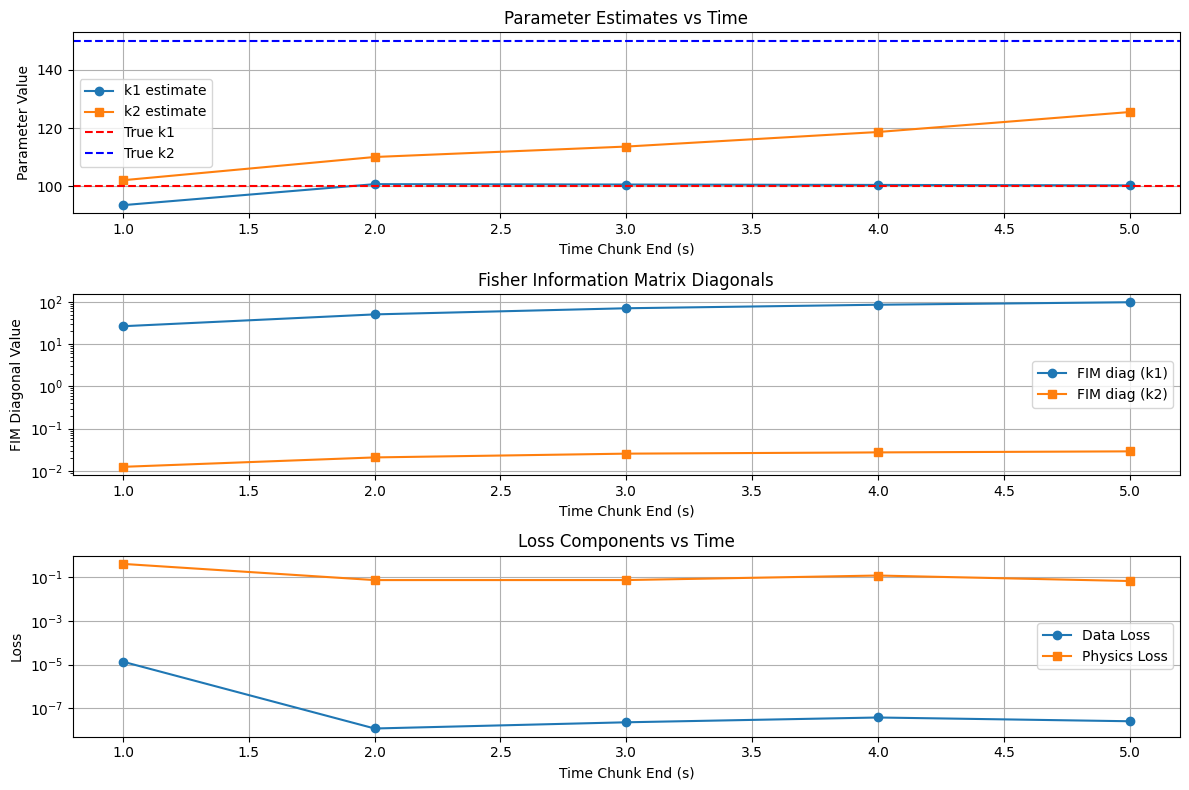

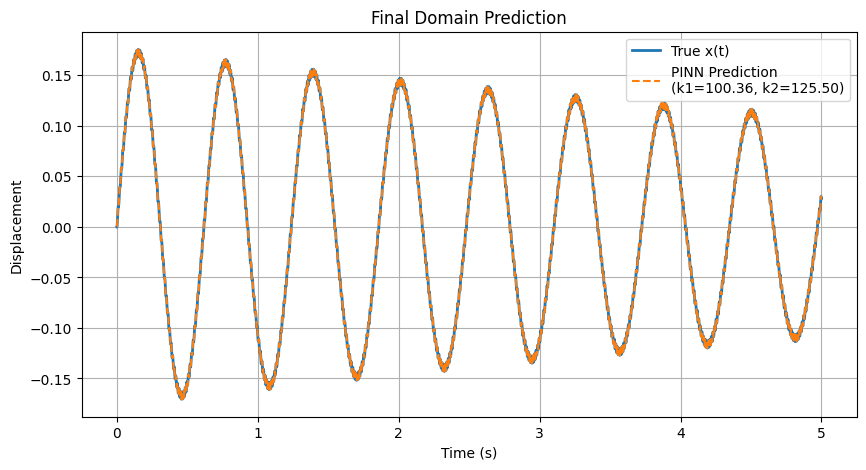

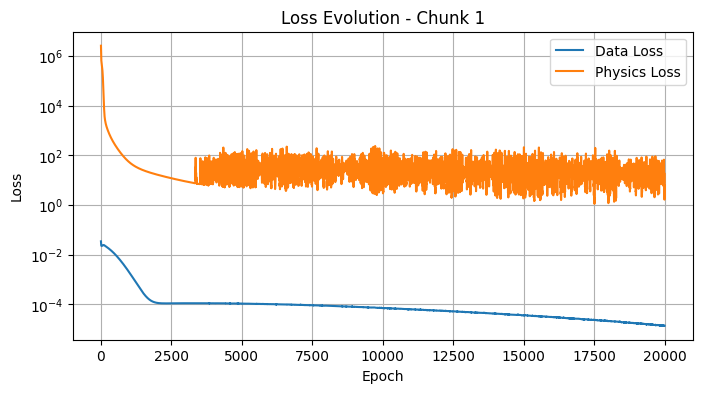

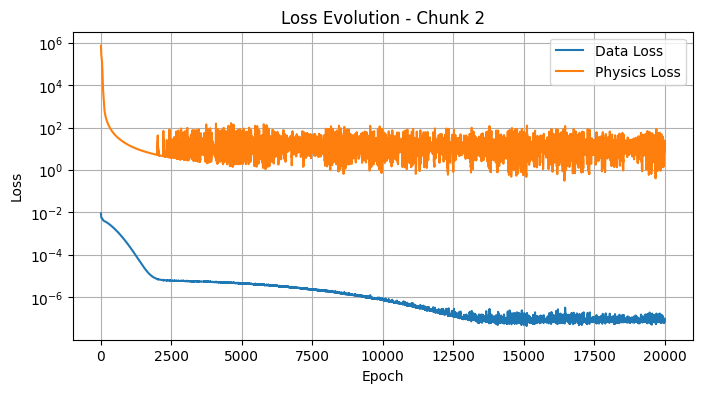

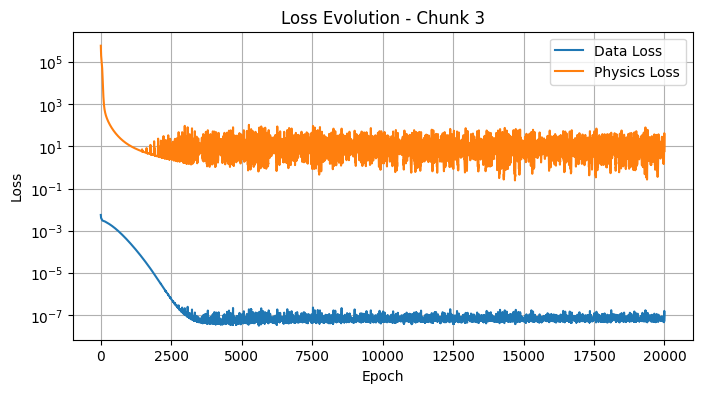

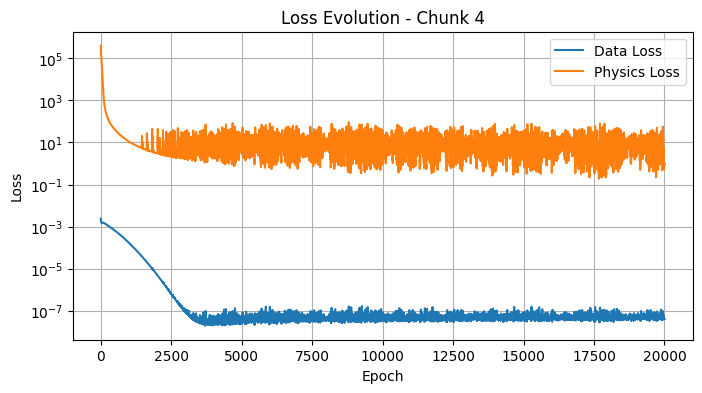

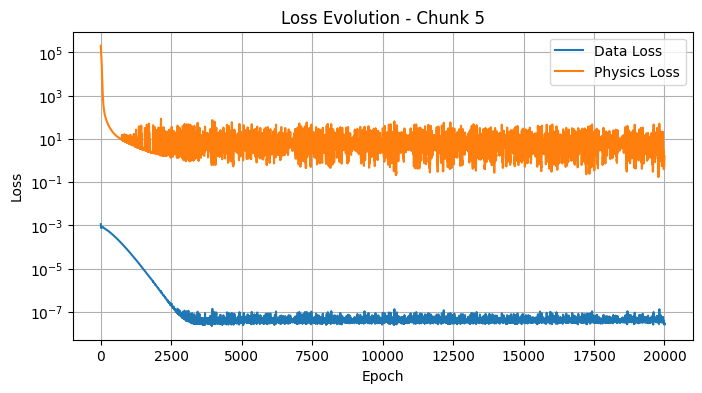

In [ ]:
#### Figure 
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import math
from torch.optim import Adam, LBFGS
from torch.autograd import grad
from torch.autograd.functional import jacobian

# =============================================
# 1. Configuration
# =============================================
class Config:
    m = 1.0
    c = 0.2
    k1_true = 100.0
    k2_true = 150.0
    omega = 90.0

    t_max = 5.0
    num_points = 10000

    chunk_size = 1.0
    adam_epochs = 20_000
    lbfgs_epochs = 200
    lr_model = 1e-4
    lr_params = 1e-3

    if torch.cuda.is_available():
        device = torch.device("cuda")
    elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
        device = torch.device("mps")
    else:
        device = torch.device("cpu")

    torch.manual_seed(1756)
    np.random.seed(1756)


# =============================================
# 2. Data Generator: Duffing Oscillator
# =============================================
class DataGenerator:
    def __init__(self, cfg: Config):
        self.cfg = cfg

    def forcing(self, t: np.ndarray) -> np.ndarray:
        return (
            1000.0 * np.sin(2 * np.pi * self.cfg.omega * t)
            + 500.0 * np.cos(2 * np.pi * self.cfg.omega * t)
        )

    def rhs(self, t: float, y: np.ndarray) -> list:
        x, v = y
        f = self.forcing(np.array([t]))[0]
        dxdt = v
        dvdt = (f - self.cfg.c * v - self.cfg.k1_true * x - self.cfg.k2_true * x**3) / self.cfg.m
        return [dxdt, dvdt]

    def generate(self) -> (np.ndarray, np.ndarray):
        t_eval = np.linspace(0.0, self.cfg.t_max, self.cfg.num_points)
        sol = solve_ivp(self.rhs, [0.0, self.cfg.t_max], [0.0, 0.0], t_eval=t_eval, method='RK45')
        return sol.t, sol.y[0]


# =============================================
# 3. PINN Model Definition
# =============================================
class FourierLayer(nn.Module):
    def __init__(self, in_features: int, out_features: int, scale: float = 10.0):
        super().__init__()
        B = torch.normal(mean=torch.ones(in_features, out_features), std=1.0) * scale
        self.register_buffer("B", B)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x_proj = 2 * math.pi * x @ self.B
        return torch.cat([torch.sin(x_proj), torch.cos(x_proj)], dim=-1)


class PINNModel(nn.Module):
    def __init__(self, fourier_features=512, hidden_features=64, hidden_layers=2):
        super().__init__()
        self.fourier = FourierLayer(1, fourier_features)
        input_dim = 2 * fourier_features
        layers = [nn.Linear(input_dim, hidden_features), nn.Tanh()]
        for _ in range(hidden_layers - 1):
            layers += [nn.Linear(hidden_features, hidden_features), nn.Tanh()]
        layers.append(nn.Linear(hidden_features, 1))
        self.net = nn.Sequential(*layers)

    def forward(self, t: torch.Tensor) -> torch.Tensor:
        x_embed = self.fourier(t)
        return self.net(x_embed)


# =============================================
# 4. Trainer Class
# =============================================
class Trainer:
    def __init__(self, cfg: Config, t_full: np.ndarray, x_full: np.ndarray):
        self.cfg = cfg
        self.t_full = t_full
        self.x_full = x_full

        self.t_full_tensor = torch.tensor(t_full.reshape(-1, 1), dtype=torch.float32, device=self.cfg.device)
        self.x_full_tensor = torch.tensor(x_full.reshape(-1, 1), dtype=torch.float32, device=self.cfg.device)

        self.model = PINNModel().to(self.cfg.device)
        self.k1 = torch.tensor([80.0], requires_grad=True, dtype=torch.float32, device=self.cfg.device)
        self.k2 = torch.tensor([90.0], requires_grad=True, dtype=torch.float32, device=self.cfg.device)

        self.results = {
            'chunk_time': [],
            'k1_est': [],
            'k2_est': [],
            'fim': [],
            'data_loss': [],
            'phys_loss': [],
            'data_loss_list': [],
            'phys_loss_list': []
        }

    def compute_loss(self, t: torch.Tensor, x_obs: torch.Tensor):
        x_pred = self.model(t)
        dx = grad(x_pred, t, torch.ones_like(x_pred), retain_graph=True,create_graph=True)[0]
        d2x = grad(dx, t, torch.ones_like(dx), retain_graph=True,create_graph=True)[0]

        forcing = (1000.0 * torch.sin(2 * torch.pi * self.cfg.omega * t)
                   + 500.0 * torch.cos(2 * torch.pi * self.cfg.omega * t))

        residual = (self.cfg.m * d2x + self.cfg.c * dx + self.k1 * x_pred + self.k2 * (x_pred ** 3) - forcing)
        data_loss = torch.mean((x_pred - x_obs) ** 2)
        phys_loss = torch.mean(residual ** 2)
        total_loss = 10000.0 * data_loss + phys_loss
        return total_loss, data_loss.item(), phys_loss.item(), residual, x_pred

    def compute_fim(self, residual: torch.Tensor):
        grad_k1 = grad(residual, self.k1, grad_outputs=torch.ones_like(residual), retain_graph=True,create_graph=True)[0]
        grad_k2 = grad(residual, self.k2, grad_outputs=torch.ones_like(residual), retain_graph=True,create_graph=True)[0]
        fim = torch.zeros((2, 2), device=self.cfg.device)
        print("Sum:", torch.sum(grad_k1 ** 2))
        print("Mean:", torch.mean(grad_k1 ** 2))
        print("Shape:", grad_k1.shape)
        fim[0, 0] = torch.mean(grad_k1 ** 2)
        fim[0, 1] = torch.mean(torch.abs(grad_k1 * grad_k2))
        fim[1, 0] = fim[0, 1]
        fim[1, 1] = torch.mean(grad_k2 ** 2)
        return fim.detach().cpu().numpy()

    def compute_fim_jacobian(self, t: torch.Tensor, x_pred: torch.Tensor) -> np.ndarray:
        """
        Compute the Fisher Information Matrix using per-sample Jacobian of residuals
        w.r.t. scalar parameters [k1, k2], via torch.autograd.functional.jacobian.

        Returns: 2×2 NumPy FIM matrix.
        """
        k_params = torch.stack([self.k1, self.k2])  # Shape: (2,)
        k_params.requires_grad_(True)

        def residual_fn(params):
            k1_, k2_ = params[0], params[1]

            # Recompute residual with detached params
            t_ = t.detach().clone().requires_grad_(True)
            x_pred_ = self.model(t_)
            # x_pred_ = x_pred.detach().clone().requires_grad_(True)
            dx = grad(x_pred_, t_, torch.ones_like(x_pred_), create_graph=True, retain_graph=True)[0]
            d2x = grad(dx, t_, torch.ones_like(dx), create_graph=True, retain_graph=True)[0]

            forcing = (4000.0 * torch.sin(2 * torch.pi * self.cfg.omega * t) +
                      3000.0 * torch.cos(2 * torch.pi * self.cfg.omega * t))

            residual = self.cfg.m * d2x + self.cfg.c * dx + k1_ * x_pred_ + k2_ * (x_pred_ ** 3) - forcing
            return residual.view(-1)  # shape: (N,)

        # Compute Jacobian: shape (N, 2)
        J = jacobian(residual_fn, k_params)  # shape: (N, 2)
        J=J.squeeze(-1)
        print(J.shape)

        # Compute FIM: Jᵀ J
        fim = J.T @ J  # shape: (2, 2)

        return fim.detach().cpu().numpy()

    def compute_fim_analytic(self, x_pred: torch.Tensor):
        """
        Analytic FIM: ∂R/∂k1 = x_pred, ∂R/∂k2 = x_pred^3.
        FIM_ij = (1/N) * sum_n [ (∂R_n/∂k_i)*(∂R_n/∂k_j ) ].
        """
        x_flat = x_pred.view(-1)          # (N,)
        g1 = x_flat                      # ∂R/∂k1
        g2 = x_flat ** 3                 # ∂R/∂k2

        N = x_flat.shape[0]
        fim_11 = torch.sum(g1 * g1).item()
        fim_12 = torch.sum(g1 * g2).item()
        fim_22 = torch.sum(g2 * g2).item()

        return np.array([[fim_11, fim_12],
                         [fim_12, fim_22]])

    def train_chunk(self, chunk_end: float):
        mask = self.t_full <= chunk_end
        t_chunk_np = self.t_full[mask].reshape(-1, 1).astype(np.float32)
        x_chunk_np = self.x_full[mask].reshape(-1, 1).astype(np.float32)

        t = torch.tensor(t_chunk_np, dtype=torch.float32, device=self.cfg.device).requires_grad_(True)
        x = torch.tensor(x_chunk_np, dtype=torch.float32, device=self.cfg.device)

        optimizer_model = Adam(self.model.parameters(), lr=self.cfg.lr_model)
        optimizer_params = Adam([self.k1, self.k2], lr=self.cfg.lr_params)

        data_losses, phys_losses = [], []

        for epoch in range(self.cfg.adam_epochs):
            optimizer_model.zero_grad()
            optimizer_params.zero_grad()
            total_loss, data_loss_val, phys_loss_val, residual,_ = self.compute_loss(t, x)
            total_loss.backward()
            optimizer_model.step()
            optimizer_params.step()

            data_losses.append(data_loss_val)
            phys_losses.append(phys_loss_val)

            if epoch % 500 == 0:
                print(f"  Epoch {epoch:5d} | Loss={total_loss.item():.6e} | "
                      f"k1={self.k1.item():.4f} | k2={self.k2.item():.4f}")

        optimizer_joint = LBFGS(list(self.model.parameters()) + [self.k1, self.k2],
                                max_iter=self.cfg.lbfgs_epochs,
                                line_search_fn='strong_wolfe')

        def closure():
            optimizer_joint.zero_grad()
            loss, _, _, _,_ = self.compute_loss(t, x)
            loss.backward()
            return loss

        for _ in range(5):
            optimizer_joint.step(closure)

        final_loss, final_data_loss, final_phys_loss, residual,x_pred = self.compute_loss(t, x)
        # fim_mat = self.compute_fim(residual)
        # fim_mat = self.compute_fim_analytic(x_pred)
        fim_mat = self.compute_fim_jacobian(t,x_pred)

        self.results['chunk_time'].append(chunk_end)
        self.results['k1_est'].append(self.k1.item())
        self.results['k2_est'].append(self.k2.item())
        self.results['fim'].append(fim_mat)
        self.results['data_loss'].append(final_data_loss)
        self.results['phys_loss'].append(final_phys_loss)
        self.results['data_loss_list'].append(data_losses)
        self.results['phys_loss_list'].append(phys_losses)

        print(f" [Chunk {chunk_end:.1f}s] k1={self.k1.item():.4f}, k2={self.k2.item():.4f} | "
              f"DataLoss={final_data_loss:.4e}, PhysLoss={final_phys_loss:.4e}")
        print(f" FIM:\n{fim_mat}\n")

    def run(self):
        num_chunks = int(self.cfg.t_max / self.cfg.chunk_size)
        for i in range(1, num_chunks + 1):
            chunk_end = i * self.cfg.chunk_size
            print(f"\n=== Training on chunk up to {chunk_end:.1f}s ===")
            self.train_chunk(chunk_end)


# =============================================
# 5. Visualizer
# =============================================
class Visualizer:
    def __init__(self, cfg: Config, trainer: Trainer, t_full: np.ndarray, x_full: np.ndarray):
        self.cfg = cfg
        self.trainer = trainer
        self.t_full = t_full
        self.x_full = x_full

    def plot_all(self, save=False):
        times = np.array(self.trainer.results['chunk_time'])
        k1_est = np.array(self.trainer.results['k1_est'])
        k2_est = np.array(self.trainer.results['k2_est'])
        fim = np.stack(self.trainer.results['fim'])
        data_loss = np.array(self.trainer.results['data_loss'])
        phys_loss = np.array(self.trainer.results['phys_loss'])

        plt.figure(figsize=(12, 8))

        plt.subplot(3, 1, 1)
        plt.plot(times, k1_est, 'o-', label='k1 estimate')
        plt.plot(times, k2_est, 's-', label='k2 estimate')
        plt.axhline(self.cfg.k1_true, color='r', linestyle='--', label='True k1')
        plt.axhline(self.cfg.k2_true, color='b', linestyle='--', label='True k2')
        plt.xlabel('Time Chunk End (s)')
        plt.ylabel('Parameter Value')
        plt.title('Parameter Estimates vs Time')
        plt.legend()
        plt.grid(True)

        fim_diag = np.array([np.diag(mat) for mat in fim])
        plt.subplot(3, 1, 2)
        plt.plot(times, fim_diag[:, 0], 'o-', label='FIM diag (k1)')
        plt.plot(times, fim_diag[:, 1], 's-', label='FIM diag (k2)')
        plt.yscale('log')
        plt.xlabel('Time Chunk End (s)')
        plt.ylabel('FIM Diagonal Value')
        plt.title('Fisher Information Matrix Diagonals')
        plt.legend()
        plt.grid(True)

        plt.subplot(3, 1, 3)
        plt.plot(times, data_loss, 'o-', label='Data Loss')
        plt.plot(times, phys_loss, 's-', label='Physics Loss')
        plt.yscale('log')
        plt.xlabel('Time Chunk End (s)')
        plt.ylabel('Loss')
        plt.title('Loss Components vs Time')
        plt.legend()
        plt.grid(True)

        plt.tight_layout()
        if save:
            plt.savefig("summary_plots_low.png", dpi=600)
        plt.show()

    def plot_final_prediction(self, save=False):
        t_tensor = torch.tensor(self.t_full.reshape(-1, 1), dtype=torch.float32, device=self.cfg.device)
        with torch.no_grad():
            x_pred = self.trainer.model(t_tensor).cpu().numpy().flatten()
        plt.figure(figsize=(10, 5))
        plt.plot(self.t_full, self.x_full, label='True x(t)', linewidth=2)
        plt.plot(self.t_full, x_pred, '--', label=f'PINN Prediction\n(k1={self.trainer.k1.item():.2f}, k2={self.trainer.k2.item():.2f})')
        plt.title("Final Domain Prediction")
        plt.xlabel('Time (s)')
        plt.ylabel('Displacement')
        plt.legend()
        plt.grid(True)
        if save:
            plt.savefig("final_prediction_low.png", dpi=600)
        plt.show()

    def plot_loss_per_chunk(self, save=False):
        for i, (dlist, plist) in enumerate(zip(self.trainer.results['data_loss_list'], self.trainer.results['phys_loss_list'])):
            plt.figure(figsize=(8, 4))
            plt.plot(dlist, label='Data Loss')
            plt.plot(plist, label='Physics Loss')
            plt.yscale('log')
            plt.title(f"Loss Evolution - Chunk {i+1}")
            plt.xlabel("Epoch")
            plt.ylabel("Loss")
            plt.legend()
            plt.grid(True)
            # if save:
            #     plt.savefig(f"loss_chunk_{i+1}.png", dpi=600)
            plt.show()


# =============================================
# 6. Main Script
# =============================================

cfg = Config()
data_gen = DataGenerator(cfg)
t_np, x_np = data_gen.generate()

trainer = Trainer(cfg, t_np, x_np)
trainer.run()

viz = Visualizer(cfg, trainer, t_np, x_np)
viz.plot_all(save=True)
viz.plot_final_prediction(save=True)
viz.plot_loss_per_chunk(save=True)


Using device: cuda


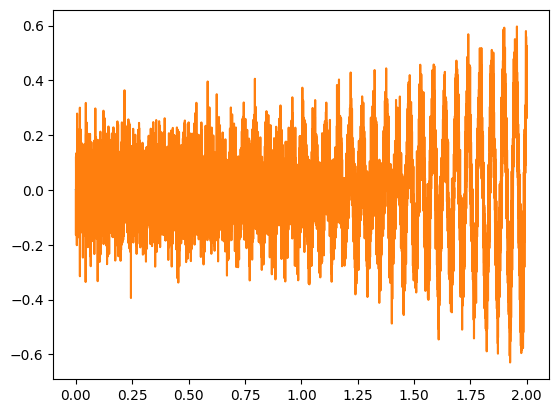

Autoanalytical   - FIM_mu_data: 1.9621e+03
Epoch 0, Loss: 1.412e+06, mu: 1.0001, Residual: 1.41e+06, Data: 2.20e-02
Epoch 500, Loss: 1.827e+03, mu: 1.0021, Residual: 3.85e+02, Data: 1.44e-02
Epoch 1000, Loss: 1.112e+03, mu: 1.0779, Residual: 1.19e+02, Data: 9.93e-03
Epoch 1500, Loss: 6.621e+02, mu: 1.1741, Residual: 8.49e+01, Data: 5.77e-03
Epoch 2000, Loss: 3.496e+02, mu: 1.2602, Residual: 6.90e+01, Data: 2.81e-03
Epoch 2500, Loss: 1.845e+02, mu: 1.3356, Residual: 5.35e+01, Data: 1.31e-03
Epoch 3000, Loss: 1.316e+02, mu: 1.4024, Residual: 4.81e+01, Data: 8.35e-04
Epoch 3500, Loss: 1.113e+02, mu: 1.4624, Residual: 4.04e+01, Data: 7.08e-04
Epoch 4000, Loss: 1.042e+02, mu: 1.5173, Residual: 3.94e+01, Data: 6.47e-04
Epoch 4500, Loss: 1.305e+02, mu: 1.5689, Residual: 7.07e+01, Data: 5.99e-04
Epoch 5000, Loss: 8.522e+01, mu: 1.6182, Residual: 2.97e+01, Data: 5.55e-04
Epoch 5500, Loss: 8.493e+01, mu: 1.6662, Residual: 3.34e+01, Data: 5.16e-04
Epoch 6000, Loss: 7.936e+01, mu: 1.7134, Residual

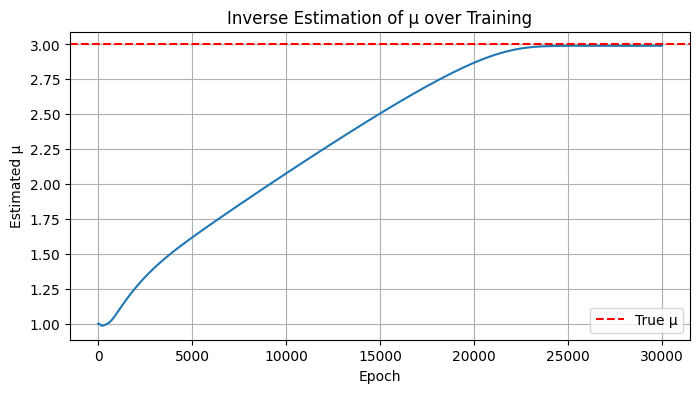

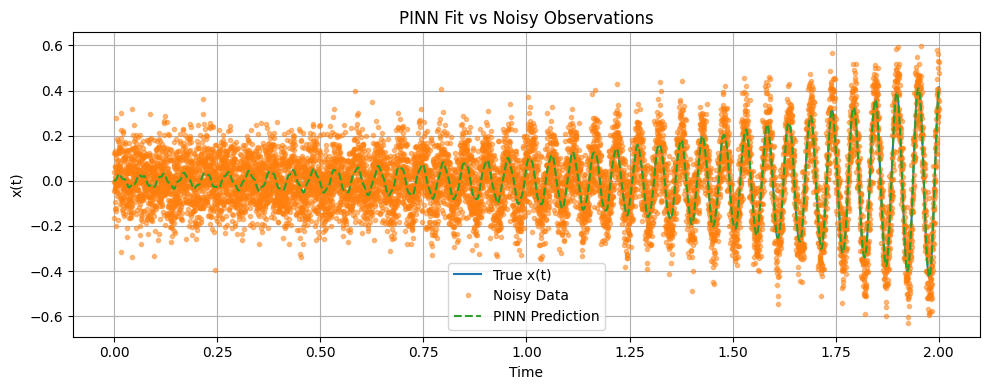

In [ ]:
# --- Imports ---
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.autograd as autograd
import matplotlib.pyplot as plt
import numpy as np
from scipy.integrate import solve_ivp
import math
from torch.autograd import grad


# --- Device Setup ---
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Using device:", device)

class FourierLayer(nn.Module):
    def __init__(self, in_features: int, out_features: int, scale: float = 10.0):
        super().__init__()
        self.B = nn.Parameter(torch.randn(in_features, out_features) * scale)

    def forward(self, x: torch.Tensor):
        x_proj = 2 * math.pi * x @ self.B
        return torch.cat([torch.sin(x_proj), torch.cos(x_proj)], dim=-1)

class PINNModel(nn.Module):
    def __init__(self, ):
        super().__init__()
        self.ff = 512
        self.fourier = FourierLayer(1, self.ff)
        self.neuron = 30
        input_dim = 2 * self.ff
        layers = [nn.Linear(input_dim, self.neuron ), nn.Tanh()]
        for _ in range(3 - 1):
            layers += [nn.Linear(self.neuron ,self.neuron ), nn.Tanh()]
        layers.append(nn.Linear(self.neuron , 1))
        self.net = nn.Sequential(*layers)
        self.mu = nn.Parameter(torch.tensor(1.0))

    def forward(self, t: torch.Tensor):
        x_embed = self.fourier(t)
        return self.net(x_embed)


# --- Forcing Function ---
def forcing_function_torch(t):
    return 1000 * torch.sin(400* t) #+250 * torch.cos(2*3.14*900* t)

# NumPy version
def forcing_function_np(t):
    return 1000 * np.sin(400 * t) #+ 250 * np.cos(2*3.14*900*t)

# --- ODE Solver for Ground Truth ---
def solve_ode_rk45_vdp(t_span, t_eval, mu, omega, x0=0.0, v0=0.0):
    def ode_system(t, y):
        x, dx = y
        f = forcing_function_np(t)
        ddx = -mu * (x**2 - 1) * dx - omega**2 * x + f
        return [dx, ddx]

    sol = solve_ivp(ode_system, t_span, [x0, v0], t_eval=t_eval, method='RK45', rtol=1e-8, atol=1e-8)
    return sol.t, sol.y[0],sol.y[1]

# --- PINN Loss Function (mu is now internal) ---
def pinn_loss_vdp_inverse(model, t, omega, x_dat):
    t.requires_grad_(True)
    x = model(t)
    dx = autograd.grad(x, t, grad_outputs=torch.ones_like(x), create_graph=True)[0]
    ddx = autograd.grad(dx, t, grad_outputs=torch.ones_like(dx), create_graph=True)[0]
    f = forcing_function_torch(t)
    mu = model.mu
    residual = ddx + mu * (x**2 - 1) * dx + (omega**2) * x - f
    res_loss = torch.mean(residual ** 2)
    data_loss = torch.mean((x - x_dat) ** 2)
    return res_loss + 1e5 * data_loss, res_loss, data_loss

mu_history = []
loss_history = []

# --- Training Loop ---
def train_inverse_mu(model, omega, t_train, x_data, epochs=5000, lr=1e-3):
    model.to(device)
    # optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    optimizer_main = torch.optim.Adam([p for n, p in model.named_parameters() if "memory" not in n], lr=1e-4)
    # optimizer_mem = torch.optim.Adam([p for n, p in model.named_parameters() if "memory" in n], lr=1e-4)



    for epoch in range(epochs):
        loss, res_loss, data_loss = pinn_loss_vdp_inverse(model, t_train, omega, x_data)
        optimizer_main.zero_grad()
        # optimizer_mem.zero_grad()
        loss.backward()
        optimizer_main.step()
        # if data_loss > 1e-2:
        #   optimizer_mem.step()

        mu_val = model.mu.item()
        mu_history.append(mu_val)
        loss_history.append(loss.item())

        if epoch % 500 == 0:
            print(f"Epoch {epoch}, Loss: {loss.item():.3e}, mu: {mu_val:.4f}, Residual: {res_loss.item():.2e}, Data: {data_loss.item():.2e}")

    return model, mu_history, loss_history

# Training parameters
t_max = 2.0
num_points = 10000
chunk_size = 2.0

# Model parameters
# fourier_features = 512
# hidden_features = 64
# hidden_layers = 2

# Training
adam_epochs = 30_000
lr_model = 1e-4
lr_params = 1e-4

# Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Reproducibility
torch.manual_seed(1756)
np.random.seed(1756)


true_mu = 3.0
omega = 120.0
x0, v0 = 0.0, 0.0
t_eval_np = np.linspace(0, t_max, num_points)
t_span = (t_eval_np[0], t_eval_np[-1])
t_np, x_np,v_np = solve_ode_rk45_vdp(t_span, t_eval_np, true_mu, omega, x0, v0)


noise_std = 0.1  # Noise std
x_noisy = x_np + np.random.normal(0, noise_std, size=x_np.shape)

t_input = torch.tensor(t_np, dtype=torch.float32).view(-1, 1).to(device)
x_data = torch.tensor(x_noisy, dtype=torch.float32).view(-1, 1).to(device)

plt.plot(t_np,x_np)
plt.plot(t_np,x_noisy)
plt.show()

def compute_fim_analytical_1(x,dx):
    """Analytical FIM for Van der Pol with forcing"""
    # x = model(t)
    # dx = grad(x, t, torch.ones_like(x), create_graph=True)[0]

    # Fisher Information for mu
    J_mu = (x**2 - 1) * dx
    fim_mu = np.abs(np.sum(J_mu))
    return fim_mu

fim_data = compute_fim_analytical_1(x_np,v_np)


print(f"Autoanalytical   - FIM_mu_data: {fim_data:.4e}")


def compute_fim_analytical(model: nn.Module, t: torch.Tensor):
    """Analytical FIM for Van der Pol with forcing"""
    x = model(t)
    dx = grad(x, t, torch.ones_like(x), create_graph=True)[0]

    # Fisher Information for mu
    J_mu = (x**2 - 1) * dx
    fim_mu = np.abs(torch.sum(J_mu).item())


    return {'mu': fim_mu}

def compute_fim_analytical_1(x,dx):
    """Analytical FIM for Van der Pol with forcing"""
    # x = model(t)
    # dx = grad(x, t, torch.ones_like(x), create_graph=True)[0]

    # Fisher Information for mu
    J_mu = (x**2 - 1) * dx
    fim_mu = np.abs(np.sum(J_mu))
    return fim_mu


def compute_fim_autograd(model: nn.Module, t: torch.Tensor,mu: torch.Tensor):
    """Autograd-based FIM computation"""
    # First-order gradients
    x = model(t)
    dx = grad(x, t, torch.ones_like(x), create_graph=True)[0]
    forcing = forcing_function_torch(t)

    # Compute log-likelihood gradient
    residual = (grad(dx, t, torch.ones_like(dx), create_graph=True)[0]
               + mu * (x**2 - 1) * dx
               + omega**2 * x
               - forcing)
    # mu=model.mu
    # Compute score function
    score_mu = grad(residual, model.mu, grad_outputs=torch.ones_like(residual), retain_graph=True)[0]
    # score_omega = grad(residual, omega, grad_outputs=torch.ones_like(residual))[0]

    # Fisher Information Matrix
    fim_mu = torch.abs(score_mu).item()
    # fim_omega = torch.mean(score_omega**2).item()

    return {'mu': fim_mu}
# =============================================
# 6. Corrected Training Loop
# =============================================
model = PINNModel().to(device)
# Training
chunk_sec = chunk_size
fim_ana_history = []
fim_auto_history = []
while chunk_sec <=t_max:
    mask = t_np <= chunk_sec
    t_chunk = torch.tensor(t_np[mask].reshape(-1, 1),
                          dtype=torch.float32,
                          device=device,
                          requires_grad=True)
    x_chunk = torch.tensor(x_np[mask].reshape(-1, 1),
                          dtype=torch.float32,
                          device=device)

    v_chunk = torch.tensor(v_np[mask].reshape(-1, 1),
                          dtype=torch.float32,
                          device=device)

    trained_model, mu_hist, loss_hist = train_inverse_mu(model, omega, t_chunk, x_chunk, epochs=adam_epochs)

    # Compute FIM both ways
    fim_ana = compute_fim_analytical(model, t_chunk,)
    fim_auto = compute_fim_autograd(model, t_chunk,model.mu)
    fim_data = compute_fim_analytical_1(x_chunk.detach().cpu().numpy(),v_chunk.detach().cpu().numpy())


    print(f"\nFIM Analysis [Chunk {chunk_sec:.1f}s]:")
    print(f"Analytical - FIM_mu: {fim_ana['mu']:.4e}")
    print(f"Autograd   - FIM_mu: {fim_auto['mu']:.4e}")
    print(f"Autoanalytical   - FIM_mu_data: {fim_data:.4e}")
    fim_ana_history.append(fim_ana['mu'])
    fim_auto_history.append(fim_auto['mu'])

    with torch.no_grad():
      # --- Plot: mu Estimate vs Epoch ---
        plt.figure(figsize=(8, 4))
        plt.plot(mu_hist)
        plt.axhline(y=true_mu, color='r', linestyle='--', label='True μ')
        plt.xlabel("Epoch")
        plt.ylabel("Estimated μ")
        plt.title("Inverse Estimation of μ over Training")
        plt.grid(True)
        plt.legend()
        # plt.savefig(f"vdp_estimate_nonidentifiable.png",dpi=600)
        plt.show()

        # --- Plot: Final Prediction vs Ground Truth ---
        model.eval()
        with torch.no_grad():
            x_pred = model(t_input).cpu().numpy()

        plt.figure(figsize=(10, 4))
        plt.plot(t_np, x_np, label='True x(t)')
        plt.plot(t_np, x_noisy, '.', alpha=0.5, label='Noisy Data')
        plt.plot(t_np, x_pred, '--', label='PINN Prediction')
        plt.xlabel("Time")
        plt.ylabel("x(t)")
        plt.title("PINN Fit vs Noisy Observations")
        plt.legend()
        plt.grid(True)
        plt.tight_layout()
        # plt.savefig(f"vdp_nonidentifiable.png",dpi=600)
        plt.show()


    chunk_sec += chunk_size

Evaluating samples: 100%|███████████████| 25000/25000 [00:06<00:00, 4008.38it/s]


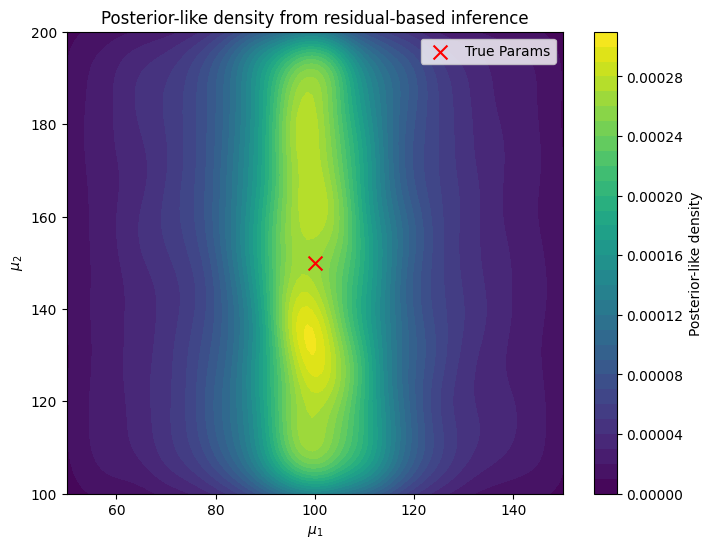

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
from tqdm import tqdm

# 1. Duffing Oscillator Function
def duffing_oscillator(t, F, mu1, mu2, mass=1.0, damp=0.1, y0=[0.0, 0.0]):
    dt = t[1] - t[0]
    y = np.zeros_like(t)
    dy = np.zeros_like(t)
    ddy = np.zeros_like(t)
    y[0], dy[0] = y0

    for i in range(1, len(t)):
        ddy[i-1] = (F[i-1] - damp*dy[i-1] - mu1*y[i-1] - mu2*y[i-1]**3) / mass
        dy[i] = dy[i-1] + ddy[i-1]*dt
        y[i] = y[i-1] + dy[i-1]*dt

    return y, dy, ddy

# 2. Time & Forcing Setup
mass = 1.0
damp = 0.1
total_time = 5.0
dt = 0.001
t = np.arange(0, total_time, dt)

def forcing(t):
    return 1000*np.sin(2*np.pi*90*t) + 500*np.cos(2*np.pi*90*t)

F = forcing(t)

# 3. Reference Output
mu1_ref = 100
mu2_ref = 150
y_ref, dy_ref, ddy_ref = duffing_oscillator(t, F, mu1_ref, mu2_ref)

# 4. Sample Parameters
n_samples = 25000
mu1_samples = np.random.uniform(50, 150, size=n_samples)
mu2_samples = np.random.uniform(100, 200, size=n_samples)
samples = np.column_stack((mu1_samples, mu2_samples))

# 5. Evaluate MSE for Each Sample (using residual between model and F)
mse_values = []

for mu1, mu2 in tqdm(samples, desc="Evaluating samples"):
    residual = mass * ddy_ref + damp * dy_ref + mu1 * y_ref + mu2 * y_ref**3 - F
    mse = np.mean(residual**2)
    mse_values.append(mse)

mse_values = np.array(mse_values)

# 6. Perform Kernel Density Estimation Weighted by Inverse MSE (as pseudo-likelihood)
inv_mse = 1 / (mse_values + 1e-8)  # avoid div by zero
weights = inv_mse / np.sum(inv_mse)
kde = gaussian_kde(samples.T, weights=weights)

# 7. Evaluate on grid and plot
mu1_grid, mu2_grid = np.mgrid[50:150:100j, 100:200:100j]
grid_coords = np.vstack([mu1_grid.ravel(), mu2_grid.ravel()])
density = kde(grid_coords).reshape(mu1_grid.shape)

plt.figure(figsize=(8, 6))
plt.contourf(mu1_grid, mu2_grid, density, levels=30, cmap='viridis')
plt.colorbar(label='Posterior-like density')
plt.scatter(mu1_ref, mu2_ref, color='red', marker='x', s=100, label='True Params')
plt.xlabel(r'$\mu_1$')
plt.ylabel(r'$\mu_2$')
plt.title("Posterior-like density from residual-based inference")
plt.legend()
plt.show()